SECTION 1: Project Introduction

Semiconductor Chip Failure Prediction
Problem Statement
Semiconductor manufacturing generates thousands of chips every day. A small defect can cause a chip to fail quality testing.

The objective of this project is to build a Machine Learning model that predicts whether a chip will pass or fail based on manufacturing measurements.

Project Goals
Understand the dataset
Perform Exploratory Data Analysis
Clean and preprocess data
Build Machine Learning models
Compare model performance
Deploy the best model using Streamlit

SECTION 2: Import Libraries

Importing Required Libraries
The following libraries are used for data analysis, visualization, machine learning and deployment.

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

import joblib
import warnings

warnings.filterwarnings("ignore")

Loading the Dataset


In [3]:
df = pd.read_csv("data/semiconductor_chip_data.csv")

In [4]:
df.head()

,chip_id,temperature_c,voltage_v,frequency_mhz,current_a,power_consumption_mw,leakage_current_ua,test_duration_sec,manufacturing_process,defect_rate,chip_failure,defect_severity,risk_level
0,CHIP-006253,67.09,1.1278,2292.37,0.2643,297.29,2.280,23.78,FD-SOI,0.01751,0,High,Medium
1,CHIP-004685,47.21,1.1196,2171.66,0.2967,330.93,1.269,19.47,FinFET,0.01084,0,Medium,Medium
2,CHIP-001732,54.63,1.0810,2848.63,0.3099,339.42,0.067,26.87,FD-SOI,0.01807,0,High,Low
3,CHIP-004743,53.74,1.1327,2282.64,0.2826,323.18,3.623,21.87,FinFET,0.01200,0,Medium,Low
4,CHIP-004522,58.82,1.0178,2416.90,0.2727,280.24,2.518,17.39,Gate-All-Around,0.00771,0,Low,Low


In [5]:
df.shape

(10000, 13)

In [6]:
df.describe()

,temperature_c,voltage_v,frequency_mhz,current_a,power_consumption_mw,leakage_current_ua,test_duration_sec,defect_rate,chip_failure
count,9880.000000,9920.000000,10000.000000,10000.000000,10000.000000,9900.000000,10000.000000,10000.000000,10000.000000
mean,55.011416,1.101604,2404.989396,0.291610,321.709121,2.345482,20.924542,0.016725,0.183300
std,12.382217,0.080108,350.906297,0.029812,44.893175,1.658681,2.538263,0.011910,0.386932
min,20.000000,0.800000,1164.360000,0.163600,182.390000,0.050000,11.090000,0.000040,0.000000
25%,46.907500,1.047075,2168.490000,0.271300,291.565000,1.296750,19.217500,0.007857,0.000000
50%,54.900000,1.100700,2406.395000,0.291400,320.015000,2.275000,20.920000,0.014110,0.000000
75%,62.862500,1.155600,2639.747500,0.311600,349.090000,3.256000,22.652500,0.022863,0.000000
max,140.922283,1.400000,3500.000000,0.423900,884.890454,36.919835,30.750000,0.095170,1.000000


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   chip_id                10000 non-null  str    
 1   temperature_c          9880 non-null   float64
 2   voltage_v              9920 non-null   float64
 3   frequency_mhz          10000 non-null  float64
 4   current_a              10000 non-null  float64
 5   power_consumption_mw   10000 non-null  float64
 6   leakage_current_ua     9900 non-null   float64
 7   test_duration_sec      10000 non-null  float64
 8   manufacturing_process  9940 non-null   str    
 9   defect_rate            10000 non-null  float64
 10  chip_failure           10000 non-null  int64  
 11  defect_severity        10000 non-null  str    
 12  risk_level             10000 non-null  str    
dtypes: float64(8), int64(1), str(4)
memory usage: 1015.8 KB


: Missing Values Analysis

In [8]:
missing_values = df.isnull().sum()

missing_values[missing_values > 0]



temperature_c            120
voltage_v                 80
leakage_current_ua       100
manufacturing_process     60
dtype: int64

In [9]:
duplicated_value = df.duplicated().sum()
duplicated_value

np.int64(0)

Visualization

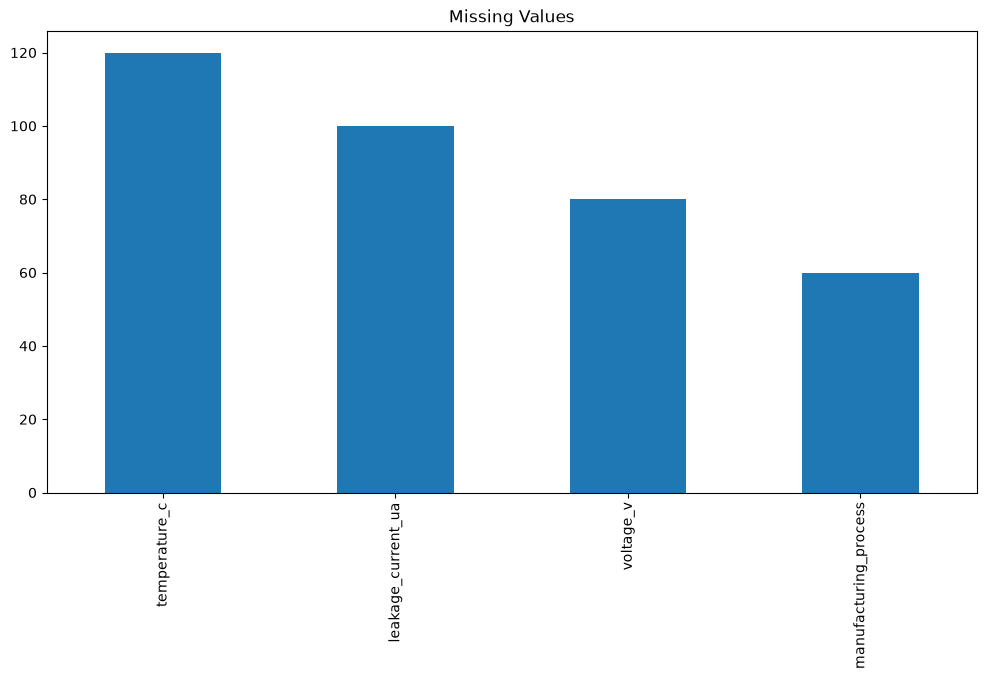

In [10]:
plt.figure(figsize=(12,6))

missing_values[missing_values > 0].sort_values(
    ascending=False
).plot(kind="bar")

plt.title("Missing Values")
plt.show()

Exploratory Data Analysis

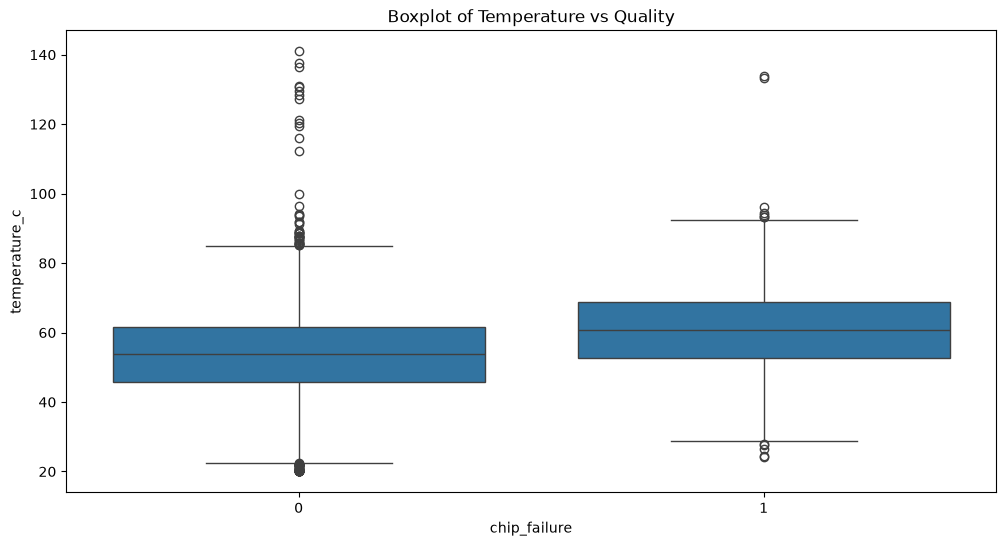

In [11]:

num_cols = [
    'temperature_c',
    'voltage_v',
    'frequency_mhz',
    'current_a',
    'power_consumption_mw',
    'leakage_current_ua',
    'test_duration_sec',
    'defect_rate'
]

plt.figure(figsize=(12,6))

sns.boxplot(x="chip_failure", y="temperature_c", data=df)
plt.title("Boxplot of Temperature vs Quality")
plt.show()

In [12]:
df.columns

Index(['chip_id', 'temperature_c', 'voltage_v', 'frequency_mhz', 'current_a',
       'power_consumption_mw', 'leakage_current_ua', 'test_duration_sec',
       'manufacturing_process', 'defect_rate', 'chip_failure',
       'defect_severity', 'risk_level'],
      dtype='str')

#Univariete Analysis of Numerical columns

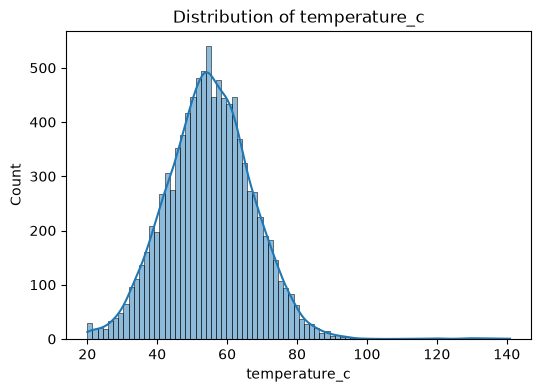

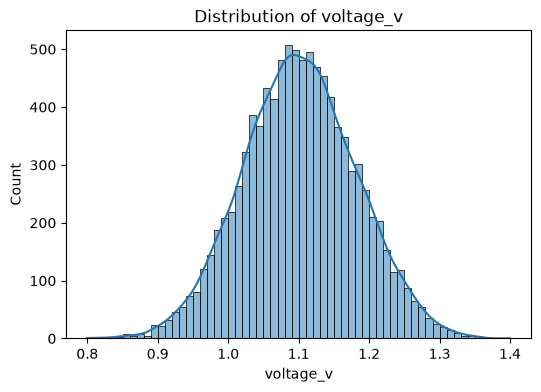

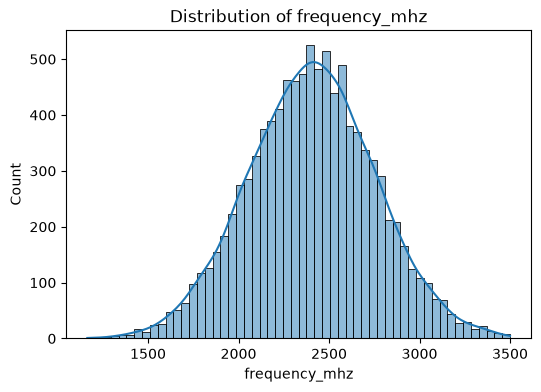

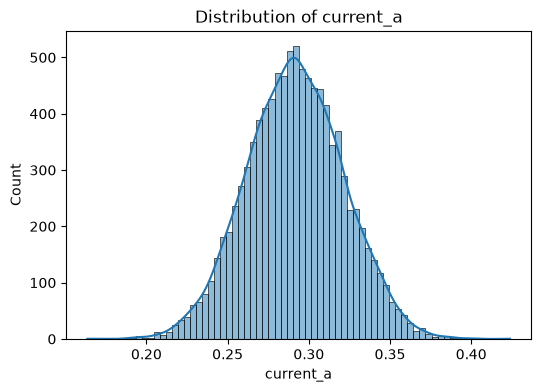

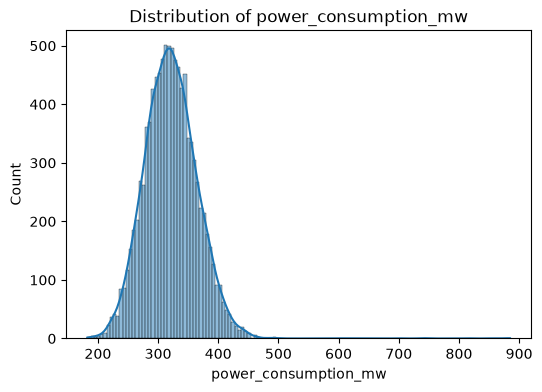

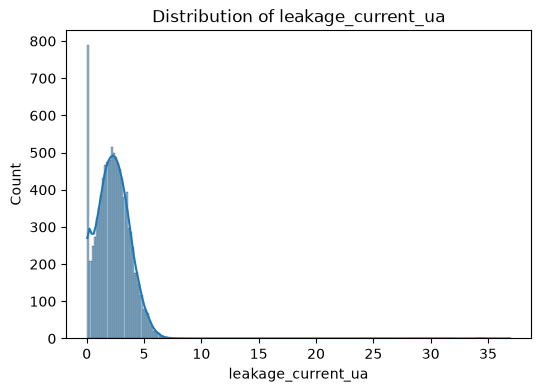

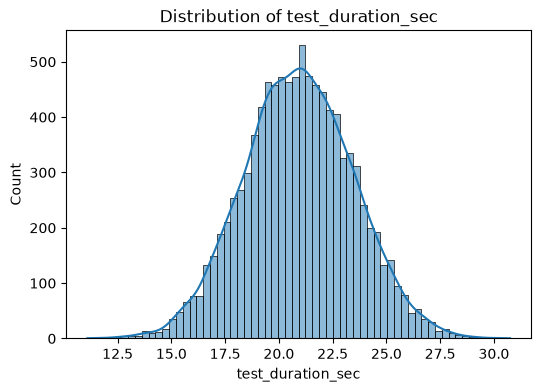

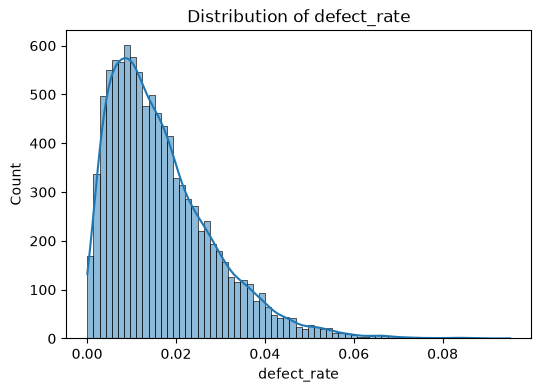

In [13]:
for col in num_cols:

    plt.figure(figsize=(6,4))

    sns.histplot(
        df[col],
        kde=True
    )

    plt.title(f"Distribution of {col}")

    plt.show()

Checking Outliers

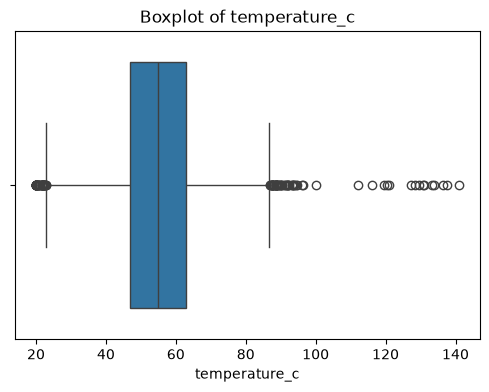

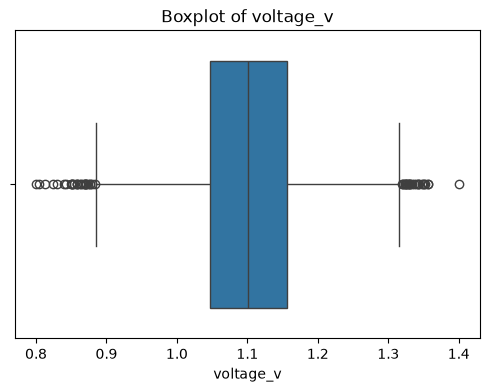

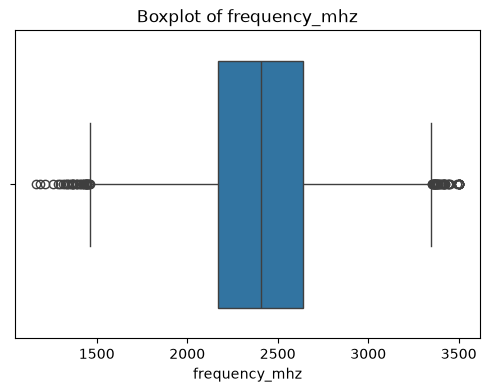

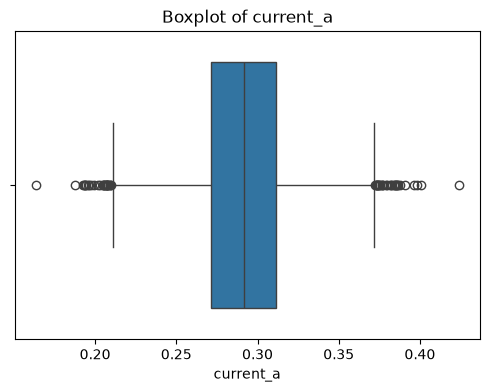

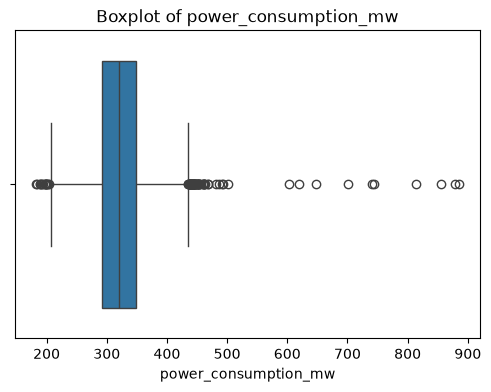

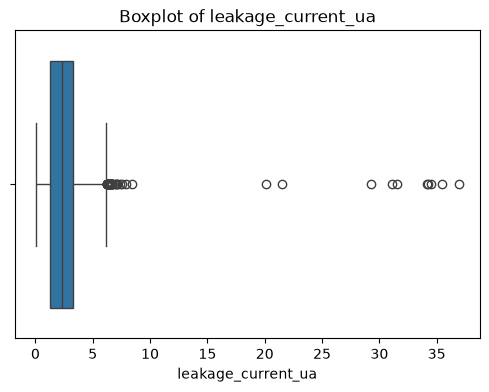

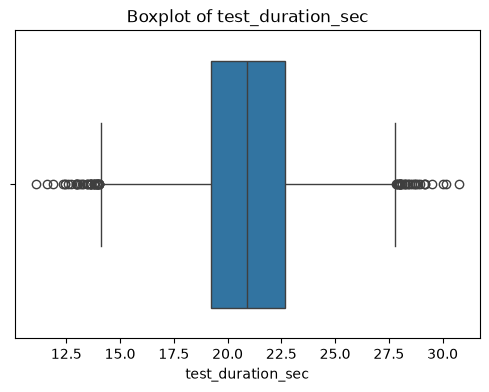

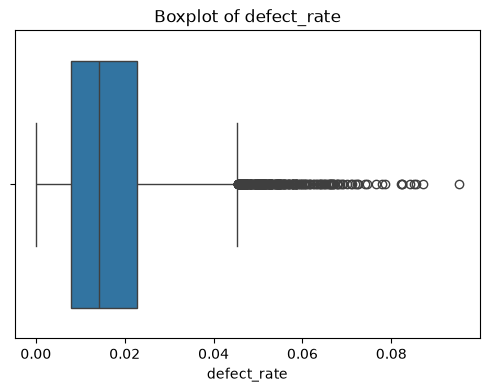

In [14]:
for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()


# Univarite Analysis of the categarical columns

In [15]:
categorical_cols = [
    'manufacturing_process',
    'defect_severity',
    'risk_level',
    'chip_failure'
]


In [16]:
df.columns

Index(['chip_id', 'temperature_c', 'voltage_v', 'frequency_mhz', 'current_a',
       'power_consumption_mw', 'leakage_current_ua', 'test_duration_sec',
       'manufacturing_process', 'defect_rate', 'chip_failure',
       'defect_severity', 'risk_level'],
      dtype='str')

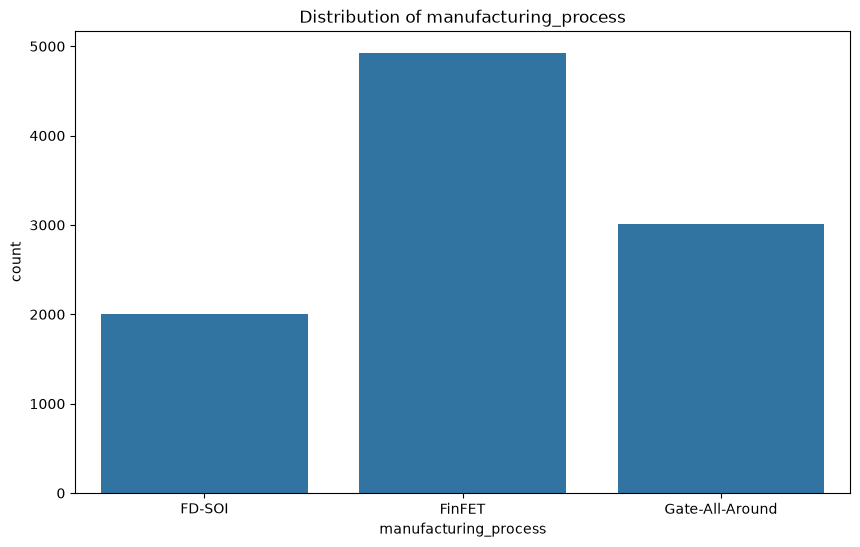

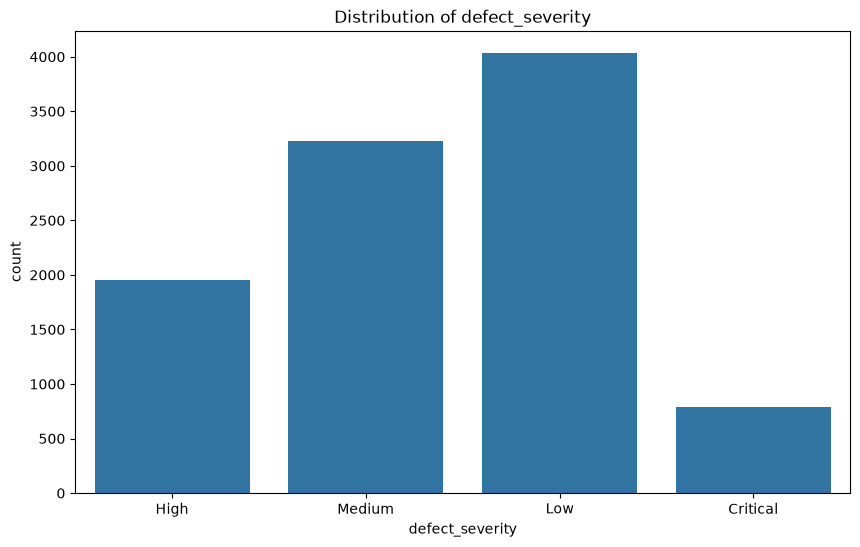

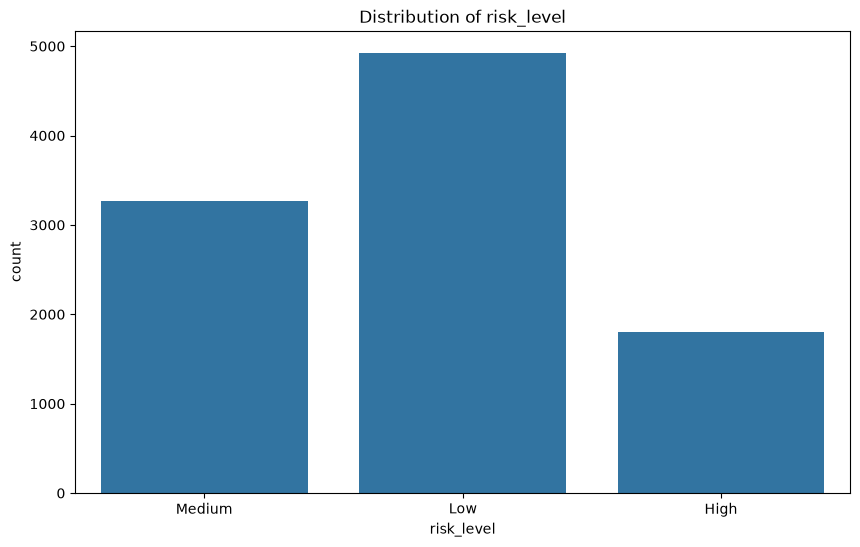

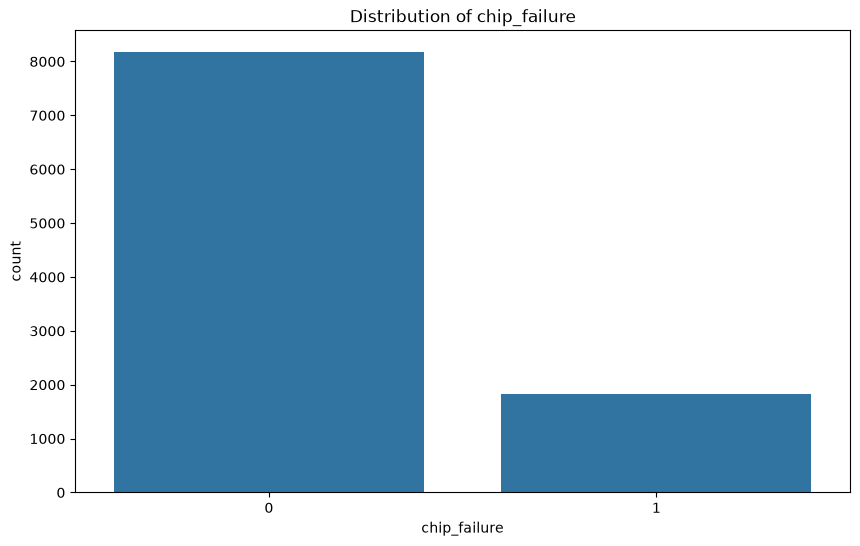

In [18]:
for col in categorical_cols:
    plt.figure(figsize=(10,6))
    sns.countplot(x=df[col], data=df)
    plt.title(f"Distribution of {col}")
    plt.show()


Target Analysis

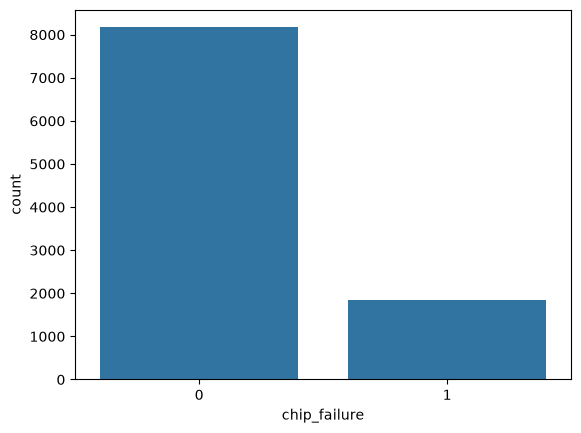

In [ ]:
sns.countplot(
    data=df,
    x='chip_failure'
)

plt.show()

Bivariate Analysis

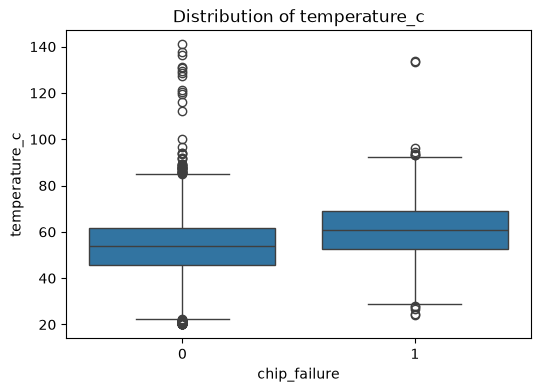

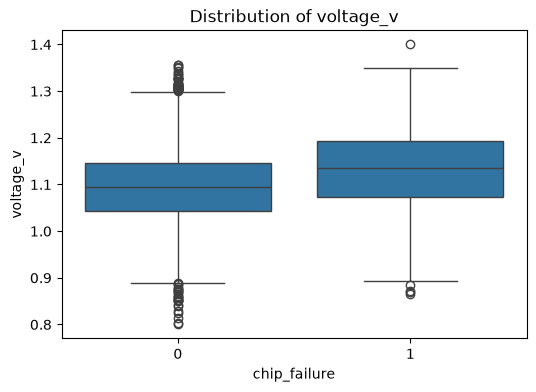

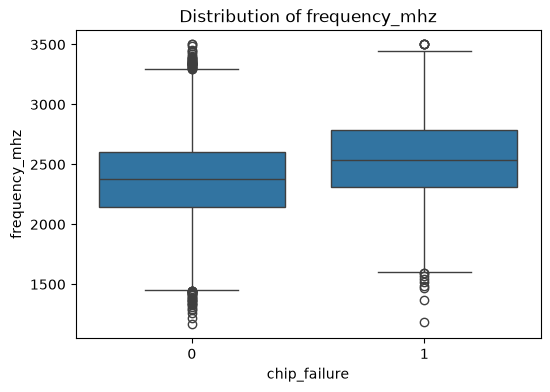

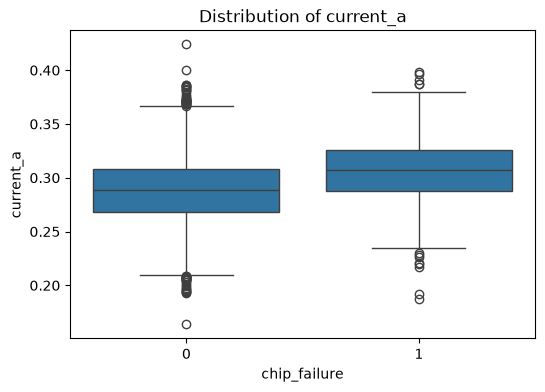

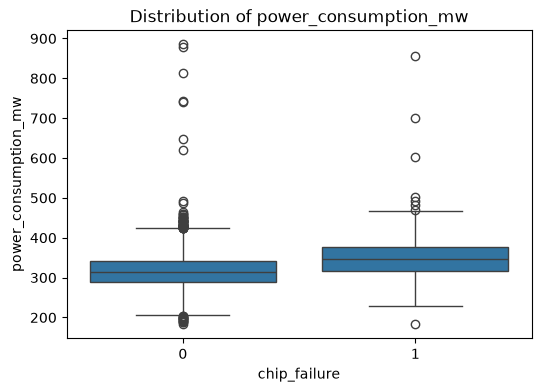

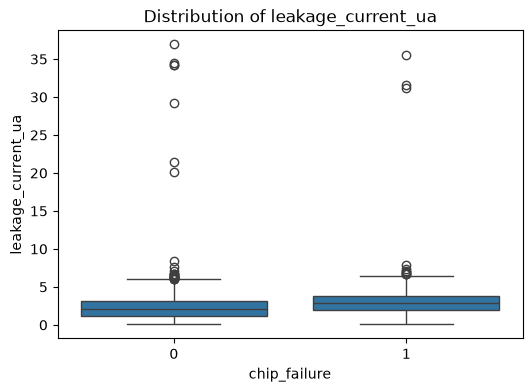

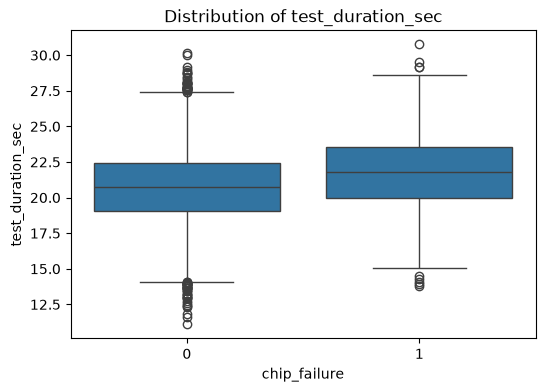

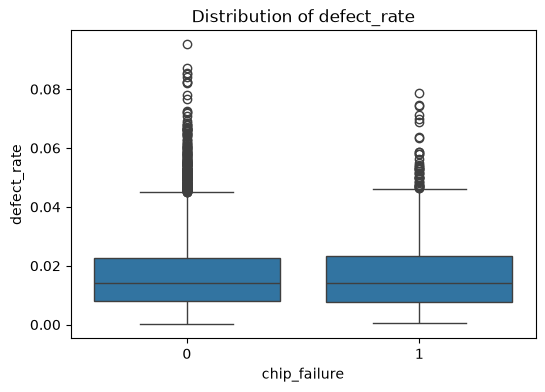

In [19]:
for col in num_cols:

    plt.figure(figsize=(6,4))

    sns.boxplot(
        x="chip_failure",
        y=df[col],
        data=df
    )

    plt.title(f"Distribution of {col}")

    plt.show()
    

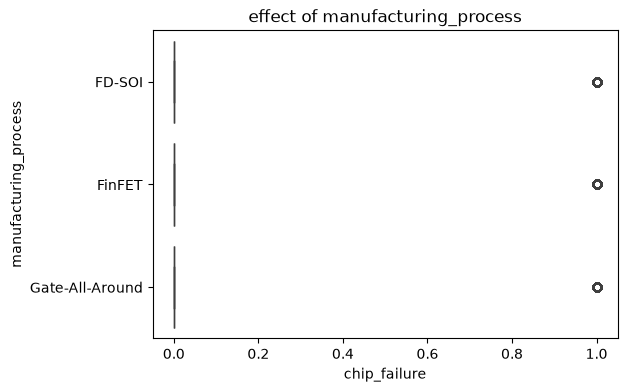

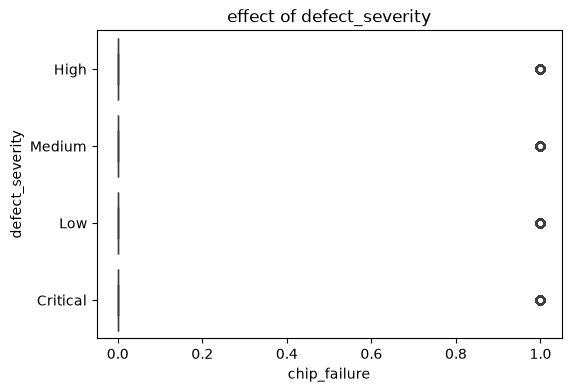

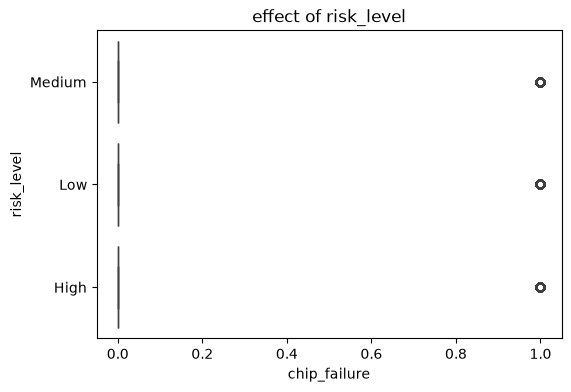

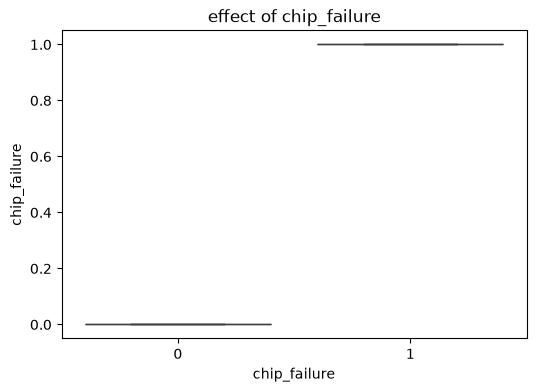

In [20]:
for col in categorical_cols:

    plt.figure(figsize=(6,4))

    sns.boxplot(
        x="chip_failure",
        y=df[col],
        data=df
    )

    plt.title(f"effect of {col}")

    plt.show()
    

#Bi variate analysis of the cat vs cat

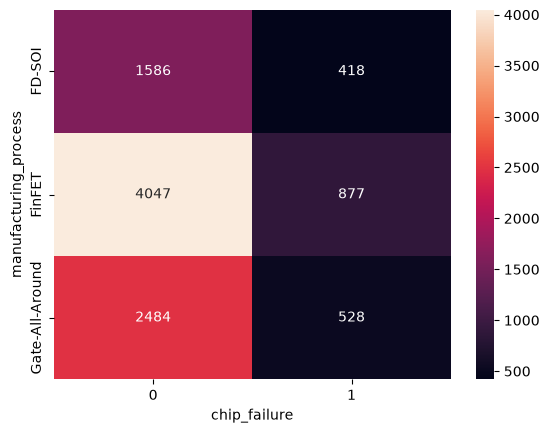

In [23]:

cross_tab=pd.crosstab(
        df["manufacturing_process"],
        df["chip_failure"]
        
    )
sns.heatmap(
        cross_tab,
        annot=True,
        fmt="d"
    )


plt.show()